<a href="https://colab.research.google.com/github/Srushti-bit/Gen-AI/blob/main/GenAi_Practical6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Input Embeddings (Hidden States):
Man: [1.9269152879714966, 1.4872840642929077, 0.9007171988487244, -2.1055209636688232]... (dimension: 16)
eat: [1.6423169374465942, -0.1595974713563919, -0.4973975419998169, 0.439589262008667]... (dimension: 16)
cheese: [-1.3846737146377563, -0.8712361454963684, -0.223365917801857, 1.7173614501953125]... (dimension: 16)
Queries (Q) Shape: torch.Size([3, 8])
Keys (K) Shape: torch.Size([3, 8])
Values (V) Shape: torch.Size([3, 8])
Attention Scores:
 [[-10.705313 -11.606056  62.89357 ]
 [-84.69232   26.995045   6.62294 ]
 [ 69.42341    5.606927 -28.202374]]

Attention Distribution (Softmax weights):
 [[1.0874531e-32 4.4179772e-33 1.0000000e+00]
 [0.0000000e+00 1.0000000e+00 1.4207163e-09]
 [1.0000000e+00 1.9268761e-28 3.9937006e-43]]
Output Attention Vectors Shape: torch.Size([3, 8])
Man attention vector: [-0.28153765201568604, 2.5002551078796387, -4.627270221710205, -0.3331648111343384, -2.7299487590789795, 0.5726194381713867, 1.9096590280532837, 3.625087

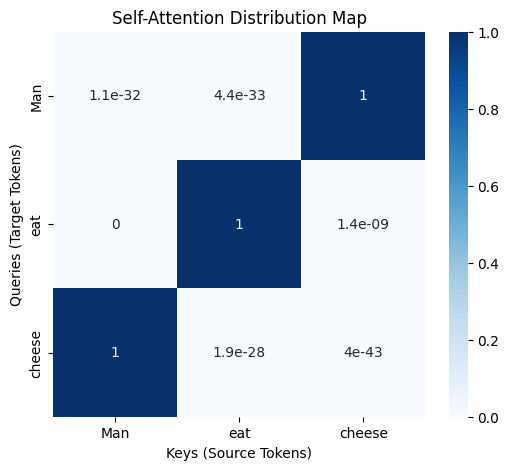

In [1]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set random seed for reproducibility
torch.manual_seed(42)

# 1. Define the input tokens and basic dimensions
tokens = ["Man", "eat", "cheese"]
seq_len = len(tokens)

# Let's define embedding dimension (d_model) and projection dimensions (d_k, d_v)
d_model = 16
d_k = 8
d_v = 8

# 2. Initialize toy embeddings for our tokens
# In a real model, these would come from an embedding layer or previous encoder layer
embeddings = torch.randn(seq_len, d_model)
print("Input Embeddings (Hidden States):")
for token, emb in zip(tokens, embeddings):
    print(f"{token}: {emb[:4].tolist()}... (dimension: {d_model})")

# 3. Define projection weights
W_q = torch.randn(d_model, d_k)
W_k = torch.randn(d_model, d_k)
W_v = torch.randn(d_model, d_v)

# Compute Q, K, V
Q = torch.matmul(embeddings, W_q)
K = torch.matmul(embeddings, W_k)
V = torch.matmul(embeddings, W_v)

print("Queries (Q) Shape:", Q.shape)
print("Keys (K) Shape:", K.shape)
print("Values (V) Shape:", V.shape)

# 4. Raw Attention Scores (Q * K^T)
attn_scores = torch.matmul(Q, K.transpose(0, 1))

# 5. Attention Distribution (Softmax)
attn_distribution = F.softmax(attn_scores, dim=-1)

print("Attention Scores:\n", attn_scores.numpy())
print("\nAttention Distribution (Softmax weights):\n", attn_distribution.numpy())

# 6. Calculate Final Attention Output Vectors
attention_output = torch.matmul(attn_distribution, V)

print("Output Attention Vectors Shape:", attention_output.shape)
for token, val in zip(tokens, attention_output):
    print(f"{token} attention vector: {val.tolist()}")

plt.figure(figsize=(6, 5))
sns.heatmap(
    attn_distribution.detach().numpy(),
    annot=True,
    xticklabels=tokens,
    yticklabels=tokens,
    cmap="Blues",
    cbar=True,
    vmin=0,
    vmax=1
)
plt.title("Self-Attention Distribution Map")
plt.xlabel("Keys (Source Tokens)")
plt.ylabel("Queries (Target Tokens)")
plt.show()